In [1]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import bootstrap

In [2]:
def ranked_probability_scores(observations, predictions):
    
    N = len(observations)
    rps = np.zeros(N)
    
    for i in range(N):
        
        observation_prob = np.array([0,0,0])
        observation_prob[observations[i]] = 1
            
        rps[i] = 1/2*( (np.cumsum(predictions[i])-np.cumsum(observation_prob))**2 ).sum()

    return rps

In [3]:
df_features = pd.read_csv('features/features_Kiefer_etal_week3.csv')
df_target = pd.read_csv('targets/northern_temperature_terc_cat_new.csv')

In [4]:
df_features['time'] = pd.to_datetime(df_features['time'])
df_features = df_features.set_index('time')

df_target['time'] = pd.to_datetime(df_target['time'])
df_target = df_target.set_index('time')

In [5]:
y_train = df_target[df_target.index < "2010-07"].values[:,0]
y_test = df_target[df_target.index >= "2010-07"].values[:,0]

In [6]:
drop = ['q850_std', 'z300_max', 'z100_max', 'z300_std', 'z500_std', 'u300_mean',
       'z300_mean', 'slp_std', 'u10_max', 'u10_mean', 'q850_mean', 'z850_min',
       't850_max', 'z100_mean', 'u300_min', 'slp_min', 't850_min', 'z500_max',
       'q850_max', 'q850_min', 'z300_min', 'slp_max', 'u300_max', 't850_mean',
       'slp_mean', 'z500_min', 'z850_std', 'u300_std', 'z850_max', 'month']
df_features_sel = df_features.drop(columns=drop)
len(df_features_sel.columns)

7

In [7]:
X_train = df_features_sel[df_features_sel.index < "2010-07"].values
X_test = df_features_sel[df_features_sel.index >= "2010-07"].values

In [8]:
classifier = RandomForestClassifier(n_estimators=1000, criterion='entropy', max_depth=None, min_samples_leaf=100, random_state=42)
classifier.fit(X_train, y_train)

y_pred = classifier.predict_proba(X_test)
rps = ranked_probability_scores(y_test, y_pred)

y_climpred = 1/3*np.ones((15*84, 3))
rps_clim = ranked_probability_scores(y_test, y_climpred)

print(rps.mean())
print(rps_clim.mean())

0.225835546870284
0.2202380952380953


In [9]:
rpss = 100*(1-rps.mean()/rps_clim.mean())
print(rpss)

-2.5415456059667774


In [10]:
mdi_importances = pd.Series(
    classifier.feature_importances_, index=df_features_sel.columns
).sort_values(ascending=True)

Text(0.5, 1.0, 'Random Forest Feature Importances (MDI)')

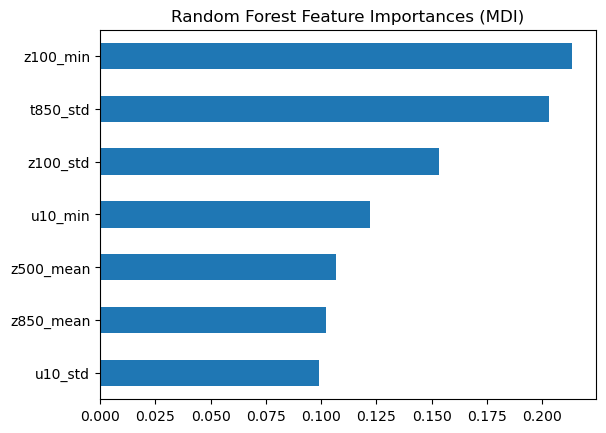

In [11]:
ax = mdi_importances.plot.barh()
ax.set_title("Random Forest Feature Importances (MDI)")

In [12]:
rps_valid = 0.20875406320763776
rpss_valid = 100*(1-rps_valid/2*9)
print(rpss_valid)

6.060671556563014


In [12]:
rps_ann = rps.reshape((15,84)).mean(axis=1)
rps_clim_ann = rps_clim.reshape((15,84)).mean(axis=1)

In [13]:
def skill_score(score, ref_score, axis=-1):
    mean = np.mean(score, axis=axis)
    mean_ref = np.mean(ref_score, axis=axis)
    return 1 - mean/mean_ref

In [14]:
skill_score(rps_ann, rps_clim_ann)

np.float64(-0.025415456059667774)

In [15]:
res = bootstrap((rps_ann, rps_clim_ann), skill_score, paired=True, confidence_level=0.90, rng=42)

In [16]:
res.confidence_interval

ConfidenceInterval(low=np.float64(-0.06846035381631954), high=np.float64(0.03232626391567897))

In [3]:
regions = ['Northern E.', 'Western-Central E.', 'Eastern E.']
skills = np.array([-0.025415456059667774,-0.005948217631097208,-0.011180885362697124])*100
lower =  np.array([-0.06846035381631954,-0.03770453177402064,-0.04184143888533523])*100
upper =  np.array([0.03232626391567897,0.015862227660913806,0.02166739295576716])*100

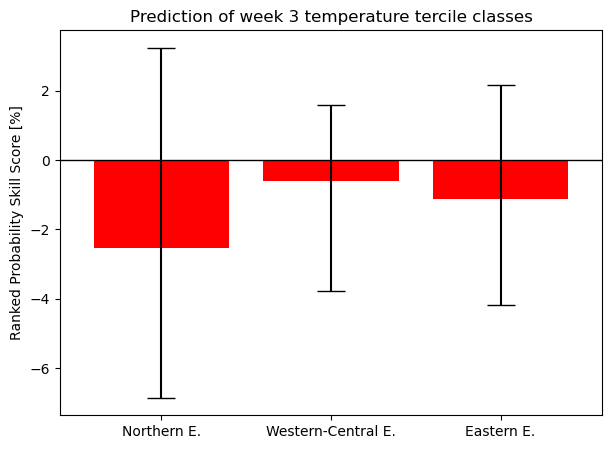

In [4]:
fig, ax = plt.subplots(figsize=(7,5))

ax.bar(regions, skills, yerr=np.stack((skills-lower, upper-skills)), capsize=10, color='red') 
ax.hlines(0, -0.6, 2.6, 'k', linewidths=1)
ax.set_xlim((-0.6, 2.6))
ax.set_ylabel('Ranked Probability Skill Score [%]')
ax.set_title('Prediction of week 3 temperature tercile classes')
plt.savefig('Kiefer_etal_temp_terc_week3_bars.pdf', bbox_inches = 'tight')

-0.005597451632188762


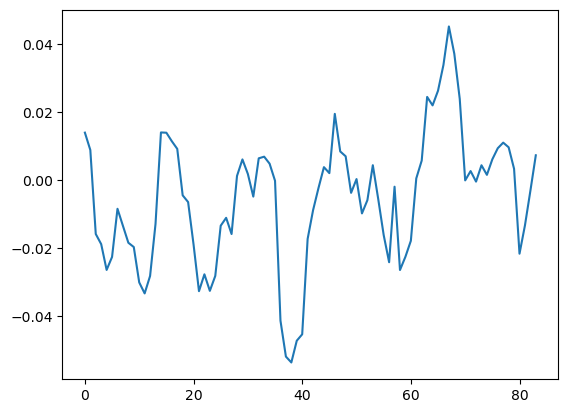

In [19]:
drps_cyc = rps_clim.reshape((15,84)).mean(axis=0) - rps.reshape((15,84)).mean(axis=0)
print(drps_cyc.mean())
plt.plot(drps_cyc)

In [20]:
lofo_rps_test = np.zeros(7)
for i in range(7):

    leave_out = df_features_sel.columns[i]
    df_features_new = df_features_sel.drop(columns=leave_out)
    X_train = df_features_new[df_features_new.index < "2010-07"].values
    X_test = df_features_new[df_features_new.index >= "2010-07"].values
    
    classifier = RandomForestClassifier(n_estimators=1000, criterion='entropy', max_depth=None, min_samples_leaf=100, random_state=42)
    classifier.fit(X_train, y_train)

    y_pred = classifier.predict_proba(X_test)
    rps = ranked_probability_scores(y_test, y_pred)
    lofo_rps_test[i] = rps.mean()

In [21]:
lofo_importances_test = lofo_rps_test - 0.225835546870284
df_importances_test = pd.Series(
    lofo_importances_test, index=df_features_sel.columns
)

Text(0.5, 0, 'Increase in RPS')

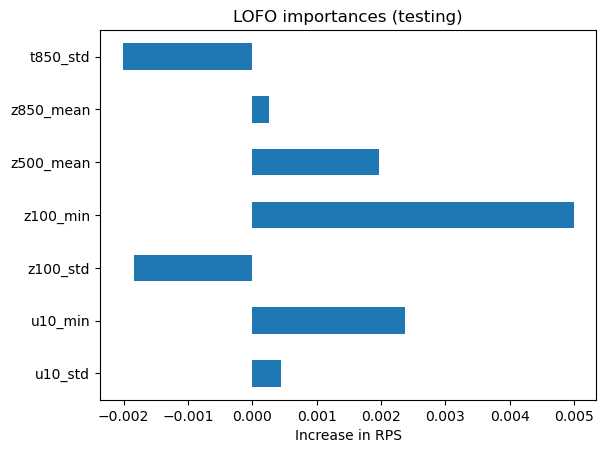

In [22]:
ax = df_importances_test.plot.barh()
ax.set_title("LOFO importances (testing)")
ax.set_xlabel("Increase in RPS")
#plt.savefig('NE_temp_terc_lofo_test.png', bbox_inches = 'tight')